In [499]:
import pandas as pd
from pathlib import Path

# Load the dataset (fail early with a clear message if the file or a column is missing)
DATA_PATH = Path('./data/classification_bonus_practice_data.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Data file not found: {DATA_PATH.resolve()}")
df = pd.read_csv(DATA_PATH)

expected_columns = ['ID', 'Survive', 'Gender', 'Smoke', 'Diabetes', 'Age', 'Ejection Fraction', 'Sodium',
                    'Creatinine', 'Platelets', 'Creatine phosphokinase', 'Blood Pressure', 'Hemoglobin',
                    'Height', 'Weight', 'Favorite color']
missing_columns = [col for col in expected_columns if col not in df.columns]
assert not missing_columns, f"Missing columns: {missing_columns}"

df_raw = df.copy()  # untouched copy of the raw data, used later to inspect repeated IDs

In [500]:
df.head()

,ID,Survive,Gender,Smoke,Diabetes,Age,Ejection Fraction,Sodium,Creatinine,Platelets,Creatine phosphokinase,Blood Pressure,Hemoglobin,Height,Weight,Favorite color
0,TIG1GE,0,Male,Yes,Normal,50,Low,141,0.7,266000.0,185,105,12.3,180,93,green
1,VXUCV9,1,Male,No,Normal,75,Low,134,2.5,224000.0,99,162,13.0,140,47,black
2,AFH4F1,1,Female,No,Pre-diabetes,80,Low,135,1.3,192000.0,776,179,12.4,150,61,white
3,ZK6PAC,0,Male,No,Normal,-60,Low,136,0.9,228000.0,2261,136,15.3,130,48,yellow
4,6CVBRT,0,Female,No,Normal,70,Low,141,0.9,358000.0,1202,171,13.3,177,64,blue


In [501]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID                      15000 non-null  object 
 1   Survive                 15000 non-null  object 
 2   Gender                  15000 non-null  object 
 3   Smoke                   15000 non-null  object 
 4   Diabetes                15000 non-null  object 
 5   Age                     15000 non-null  int64  
 6   Ejection Fraction       15000 non-null  object 
 7   Sodium                  15000 non-null  int64  
 8   Creatinine              14501 non-null  float64
 9   Platelets               15000 non-null  float64
 10  Creatine phosphokinase  15000 non-null  int64  
 11  Blood Pressure          15000 non-null  int64  
 12  Hemoglobin              15000 non-null  float64
 13  Height                  15000 non-null  int64  
 14  Weight                  15000 non-null

In [502]:
df.isnull().sum()

ID                          0
Survive                     0
Gender                      0
Smoke                       0
Diabetes                    0
Age                         0
Ejection Fraction           0
Sodium                      0
Creatinine                499
Platelets                   0
Creatine phosphokinase      0
Blood Pressure              0
Hemoglobin                  0
Height                      0
Weight                      0
Favorite color              0
dtype: int64

In [503]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,15000.0,57.428467,23.411173,-95.0,50.0,60.0,70.0,95.0
Sodium,15000.0,136.604267,4.364890,113.0,134.0,137.0,140.0,148.0
Creatinine,14501.0,1.410195,1.044535,0.5,0.9,1.1,1.4,9.4
Platelets,15000.0,263096.016490,98056.330340,25100.0,211000.0,262000.0,304000.0,850000.0
Creatine phosphokinase,15000.0,580.151800,955.418765,23.0,115.0,250.0,582.0,7861.0
Blood Pressure,15000.0,103.676667,39.700138,40.0,70.0,100.0,137.0,179.0
Hemoglobin,15000.0,12.910667,2.500152,9.0,10.7,12.7,15.1,17.5
Height,15000.0,159.475200,17.344439,130.0,144.0,160.0,174.0,189.0
Weight,15000.0,69.340467,25.298287,19.0,50.0,66.0,87.0,141.0


In [ ]:
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}\n")

# Missing values as a percentage of all rows
missing = df.isna().sum()
print((missing[missing > 0] / len(df) * 100).round(2).rename('% missing').to_frame(), '\n')

# Data quality checks that the raw summaries above hint at
print('Rows with a negative Age     :', (df['Age'] < 0).sum())
print('IDs appearing more than once :', (df['ID'].value_counts() > 1).sum(), 'of', df['ID'].nunique(), 'distinct IDs')
print('Raw Survive values           :', sorted(df['Survive'].unique()))

# Is missingness in Creatinine related to survival?
raw_target = df['Survive'].replace({'Yes': 1, 'No': 0}).astype(int)
print('\nSurvival rate when Creatinine is missing vs present:')
print(raw_target.groupby(df['Creatinine'].isna()).agg(['mean', 'count']).rename(index={False: 'present', True: 'missing'}).round(3))

Rows: 15,000 | Columns: 16

            % missing
Creatinine       3.33 

Rows with a negative Age     : 430
IDs appearing more than once : 885 of 14042 distinct IDs
Raw Survive values           : ['0', '1', 'No', 'Yes']

Survival rate when Creatinine is missing vs present:
             mean  count
Creatinine              
present     0.332  14501
missing     0.000    499


**What the initial exploration shows**

- **Size and types:** 15,000 rows and 16 columns. Seven columns are text (`ID`, `Survive`, `Gender`, `Smoke`, `Diabetes`, `Ejection Fraction`, `Favorite color`) and nine are numeric clinical measurements.
- **Missing values:** only `Creatinine` has missing values (499 rows, 3.3%). They are **not random**: 0% of patients with a missing `Creatinine` survived, compared with 33% of patients where it is recorded. Missingness therefore carries information about the target, so the modelling pipeline keeps a "was missing" flag next to the imputed value instead of only filling the gap with the median. (In practice it is worth asking why the lab value is missing, for example whether it is recorded only after the outcome is known.)
- **Anomalies found:** 430 negative ages (2.9%), `Survive` stored as text with four spellings, 885 IDs that appear more than once, and (seen later) inconsistent labels in `Smoke` and `Ejection Fraction`. Each is handled below.

### Age has negative value, to correct

In [504]:
df['Age'] = df['Age'].abs()  

**Negative ages:** 430 patients have a negative `Age`. The magnitudes are plausible ages, so the minus sign looks like a data-entry error. Taking the absolute value is therefore a reasonable fix. After it, no age falls outside the IQR fences (22.5 to 98.5) in the outlier table further down. This is an assumption worth confirming with the data owner.

In [505]:
# Drop the ID (an identifier, not a predictor) and the irrelevant Favorite color column
df.drop(columns=['Favorite color', 'ID'], inplace=True)


### Check duplicates for ID

In [506]:
df.duplicated().sum()

2

In [507]:
df[df.duplicated(keep=False)].sort_values(by=list(df.columns))

,Survive,Gender,Smoke,Diabetes,Age,Ejection Fraction,Sodium,Creatinine,Platelets,Creatine phosphokinase,Blood Pressure,Hemoglobin,Height,Weight
2885,0,Female,No,Normal,58,Low,139,1.0,164000.0,400,70,11.1,151,70
8850,0,Female,No,Normal,58,Low,139,1.0,164000.0,400,70,11.1,151,70
208,0,Male,Yes,Normal,50,Normal,140,0.8,147000.0,582,136,13.1,166,57
4374,0,Male,Yes,Normal,50,Normal,140,0.8,147000.0,582,136,13.1,166,57


In [508]:
df.drop_duplicates(inplace=True)

In [ ]:
# Are repeated IDs really the same patient? Compare the records that share an ID
repeated = df_raw[df_raw['ID'].duplicated(keep=False)].sort_values('ID')
same_person = repeated.groupby('ID')[['Gender', 'Age', 'Height', 'Weight']].nunique()
print(f"{repeated['ID'].nunique()} IDs are repeated ({len(repeated)} rows).")
print("Share of repeated IDs whose records differ in:")
print((same_person > 1).mean().round(3).rename('share differing').to_frame())
print()
print(repeated[['ID', 'Survive', 'Gender', 'Age', 'Height', 'Weight']].head(6).to_string(index=False))

885 IDs are repeated (1843 rows).
Share of repeated IDs whose records differ in:
        share differing
Gender            0.472
Age               0.963
Height            0.980
Weight            0.991

    ID Survive Gender  Age  Height  Weight
00G7VD       0 Female   65     183      64
00G7VD       1 Female   82     154      88
00IUNH       0   Male   50     172      67
00IUNH       0   Male   45     189      76
03HS9P       0 Female   50     169      44
03HS9P       0   Male   61     154      70


**Repeated IDs are not repeated patients.** 885 IDs appear more than once (1,843 rows), but the records that share an ID almost always describe different people: they differ in age (96% of repeated IDs), height (98%), weight (99%) and often gender (47%). These are random ID collisions, so `ID` carries no patient information and no patient can appear in both the training and test sets. `ID` is dropped (together with `Favorite color`, which has no clinical meaning). After that, only 2 rows are exact duplicates, and they are removed.

### Check value counts for categorical features

In [509]:
print(df['Survive'].value_counts())
print(df['Gender'].value_counts())
print(df['Smoke'].value_counts())
print(df['Diabetes'].value_counts())
print(df['Ejection Fraction'].value_counts())

Survive
0      9579
1      4552
No      604
Yes     263
Name: count, dtype: int64
Gender
Male      9756
Female    5242
Name: count, dtype: int64
Smoke
No     9709
Yes    4706
NO      399
YES     184
Name: count, dtype: int64
Diabetes
Normal          8787
Pre-diabetes    3124
Diabetes        3087
Name: count, dtype: int64
Ejection Fraction
Low       12733
Normal     1657
L           482
N            66
High         60
Name: count, dtype: int64


**Target cleaning, step by step.** The raw values of `Survive` are `'0'` (9,581), `'1'` (4,552), `'No'` (604) and `'Yes'` (263): the same two outcomes written two ways, stored as text. A model cannot be trained on this, and counting `'No'` and `'0'` as different classes would split each outcome in two. The fix maps `Yes` to 1 and `No` to 0, converts the column to integers and then asserts that only 0 and 1 remain.

In [510]:
# Map Yes/No directly to integers (existing '0'/'1' strings are converted by astype), then validate
df['Survive'] = df['Survive'].replace({'Yes': 1, 'No': 0}).astype(int)
assert set(df['Survive'].unique()) <= {0, 1}, "Survive must only contain 0 and 1"

In [511]:
df['Smoke'] = df['Smoke'].str.capitalize()

In [512]:
df['Ejection Fraction'] = df['Ejection Fraction'].replace({'L': 'Low', 'N': 'Normal'})

In [513]:
# Re-check value counts
print(df['Survive'].value_counts())
print(df['Gender'].value_counts())
print(df['Smoke'].value_counts())
print(df['Diabetes'].value_counts())
print(df['Ejection Fraction'].value_counts())

Survive
0    10183
1     4815
Name: count, dtype: int64
Gender
Male      9756
Female    5242
Name: count, dtype: int64
Smoke
No     10108
Yes     4890
Name: count, dtype: int64
Diabetes
Normal          8787
Pre-diabetes    3124
Diabetes        3087
Name: count, dtype: int64
Ejection Fraction
Low       13215
Normal     1723
High         60
Name: count, dtype: int64


**Result of the label cleaning:** `Survive` now contains only the integers 0 and 1. `Smoke` is reduced from four spellings (`No` 9,710, `Yes` 4,707, `NO` 399, `YES` 184) to the two categories `No` and `Yes`, and `Ejection Fraction` from five values (`Low` 12,734, `L` 482, `Normal` 1,658, `N` 66, `High` 60) to `Low`, `Normal` and `High`. `Ejection Fraction` is dominated by `Low`, and `High` is rare (60 patients), which matters when its effect on survival is interpreted later.

Creating Bar Chart
---------

In [514]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the plotting style once for the whole notebook
sns.set_style("whitegrid")

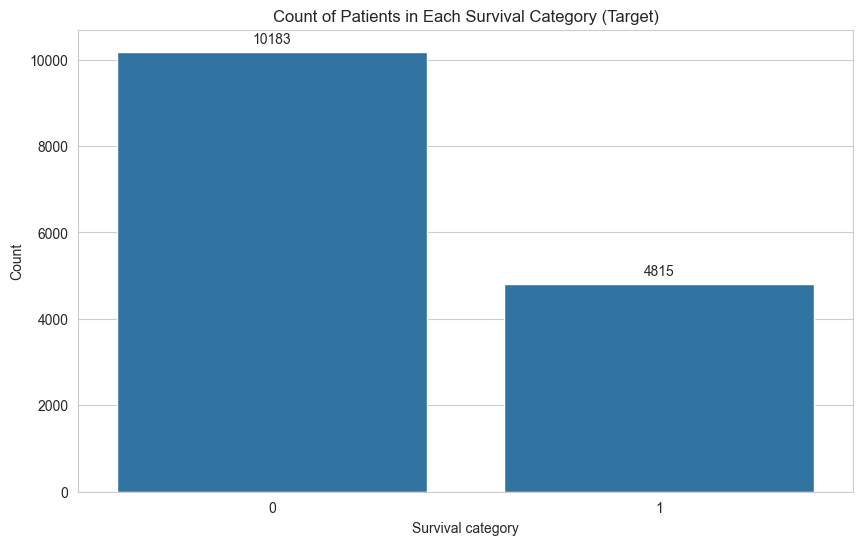

In [515]:
# Bar chart for the target (Survive) with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='Survive', data=df)
plt.title('Count of Patients in Each Survival Category (Target)')
plt.xlabel('Survival category')
plt.ylabel('Count')
#plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

In [ ]:
# Class balance as proportions, not just counts
class_share = df['Survive'].value_counts(normalize=True).sort_index().mul(100).round(1)
print(f"Did not survive (0): {class_share[0]}%")
print(f"Survived (1)       : {class_share[1]}%")
print(f"Imbalance ratio    : {df['Survive'].value_counts().max() / df['Survive'].value_counts().min():.2f} : 1")

Did not survive (0): 67.9%
Survived (1)       : 32.1%
Imbalance ratio    : 2.11 : 1


**Class balance:** 67.9% of patients did not survive and 32.1% survived (an imbalance of 2.1 : 1). This is a moderate imbalance, not an extreme one. It matters in two ways. First, always predicting "did not survive" would already be 68% accurate, so accuracy is a misleading metric and the models are judged on ROC AUC, PR AUC, precision and recall instead. Second, it justifies the later modelling choices: stratified train/validation/test splits (so every split keeps the 32% survival rate) and class-weighted models. Resampling is not needed for an imbalance of this size.

C:\Users\wongj\AppData\Local\Temp\ipykernel_6296\1890514235.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  count_plot = sns.countplot(x='Ejection Fraction', data=df, palette='pastel')


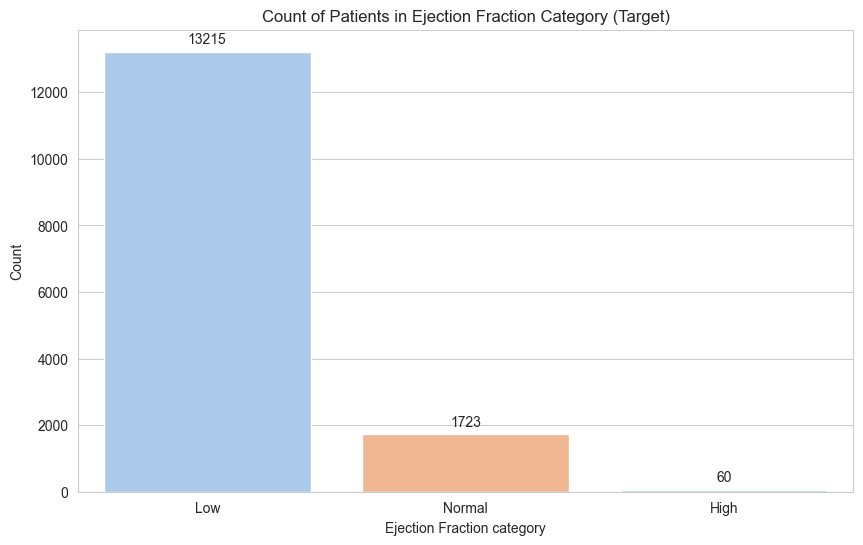

In [516]:
# Bar chart for Ejection Fraction with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='Ejection Fraction', data=df, palette='pastel')
plt.title('Count of Patients in each Ejection Fraction category')
plt.xlabel('Ejection Fraction category')
plt.ylabel('Count')
#plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

C:\Users\wongj\AppData\Local\Temp\ipykernel_6296\390164580.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  count_plot = sns.countplot(x='Smoke', data=df, palette='pastel')


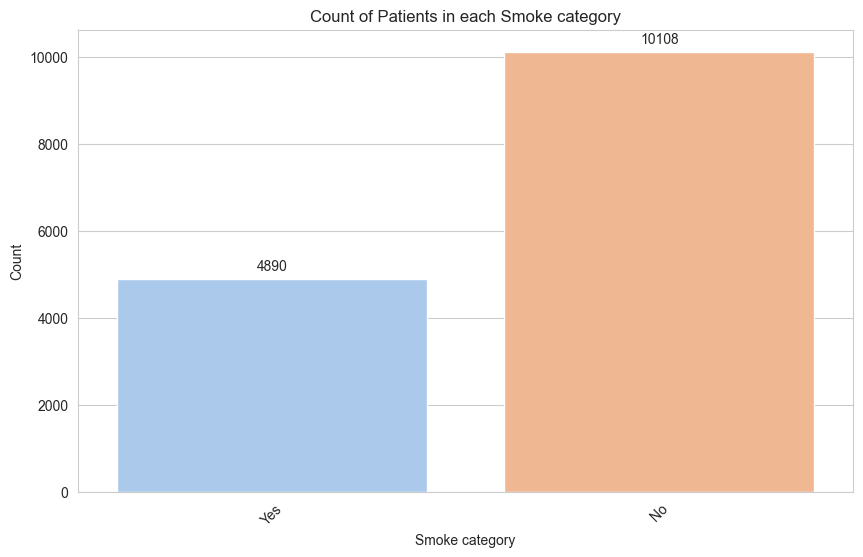

In [517]:
# Bar chart for Smoke with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='Smoke', data=df, palette='pastel')
plt.title('Count of Patients in each Smoke category')
plt.xlabel('Smoke category')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

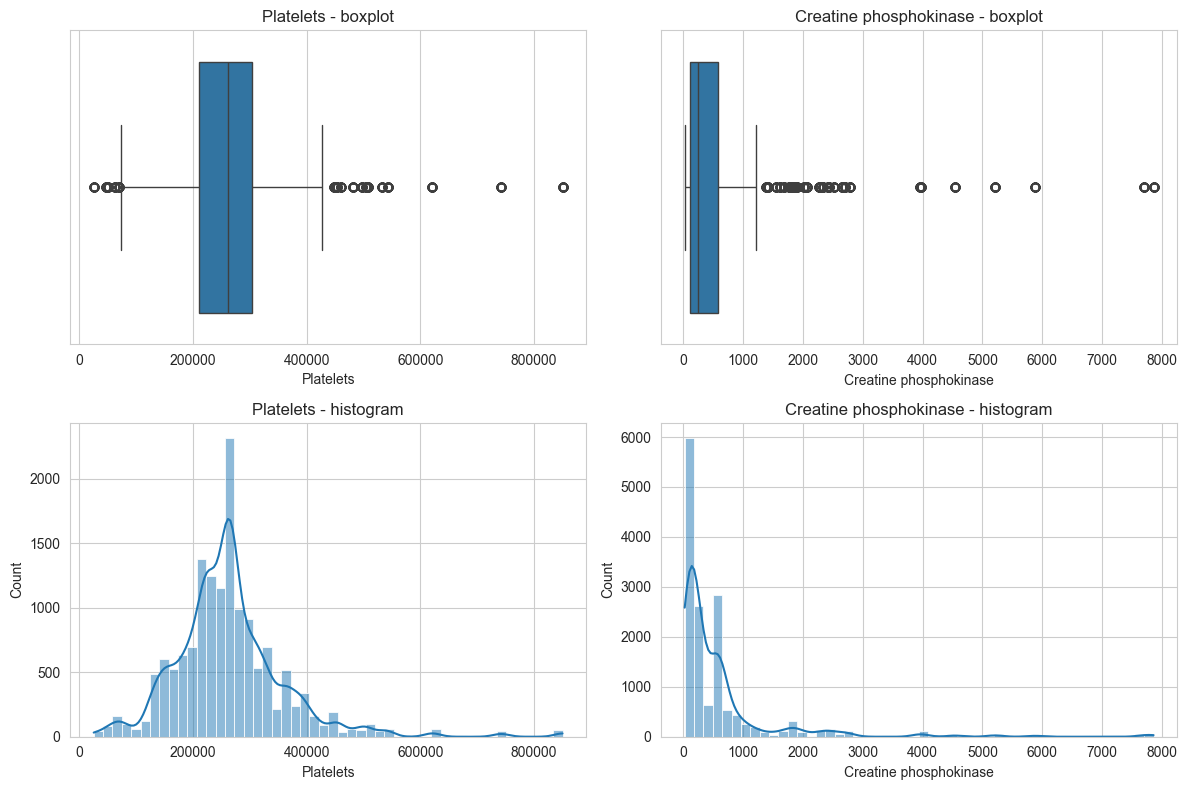

In [518]:
# Outlier analysis: boxplot + histogram
cols = ['Platelets', 'Creatine phosphokinase']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, col in enumerate(cols):
    sns.boxplot(x=df[col], ax=axes[0, i])
    axes[0, i].set_title(f'{col} - boxplot')
    sns.histplot(df[col], bins=50, kde=True, ax=axes[1, i])
    axes[1, i].set_title(f'{col} - histogram')
plt.tight_layout()
plt.show()

                        lower fence  upper fence  outliers  % outliers  skew
feature                                                                     
Age                           22.50        98.50         0        0.00  0.41
Sodium                       125.00       149.00       185        1.23 -1.00
Creatinine                     0.15         2.15      1513       10.44  4.33
Platelets                  71500.00    443500.00       941        6.27  1.50
Creatine phosphokinase      -585.50      1282.50      1483        9.89  4.38
Blood Pressure               -30.50       237.50         0        0.00  0.21
Hemoglobin                     4.10        21.70         0        0.00  0.18
Height                        99.00       219.00         0        0.00 -0.01
Weight                        -5.50       142.50         0        0.00  0.44


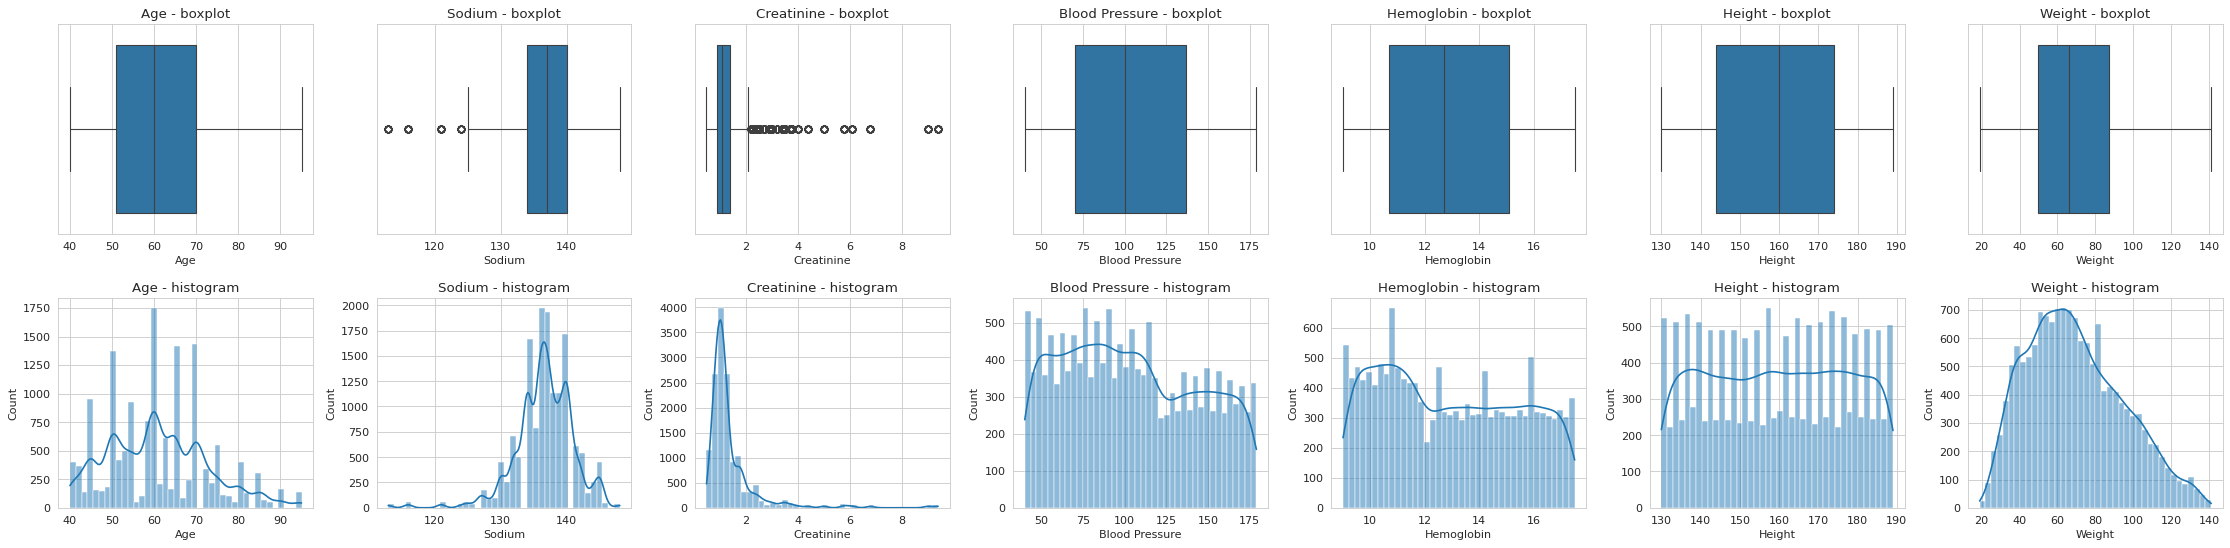

In [ ]:
# Consistent outlier analysis: boxplot + histogram for every continuous feature
# (Platelets and Creatine phosphokinase were plotted above)
continuous_cols = ['Age', 'Sodium', 'Creatinine', 'Blood Pressure', 'Hemoglobin', 'Height', 'Weight']

fig, axes = plt.subplots(2, len(continuous_cols), figsize=(4 * len(continuous_cols), 7))
for i, col in enumerate(continuous_cols):
    sns.boxplot(x=df[col], ax=axes[0, i])
    axes[0, i].set_title(f'{col} - boxplot')
    sns.histplot(df[col], bins=40, kde=True, ax=axes[1, i])
    axes[1, i].set_title(f'{col} - histogram')
plt.tight_layout()
plt.show()

# Quantitative support: IQR fences, number of outliers and skewness for all 9 continuous features
all_cols = ['Age', 'Sodium', 'Creatinine', 'Platelets', 'Creatine phosphokinase',
            'Blood Pressure', 'Hemoglobin', 'Height', 'Weight']
rows = []
for col in all_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append({'feature': col, 'lower fence': round(low, 2), 'upper fence': round(high, 2),
                 'outliers': n_out, '% outliers': round(100 * n_out / df[col].notna().sum(), 2),
                 'skew': round(df[col].skew(), 2)})
print(pd.DataFrame(rows).set_index('feature'))

**Outlier observations** (IQR fences are Q1 - 1.5 x IQR and Q3 + 1.5 x IQR):

- **`Creatinine`** is strongly right-skewed (skew 4.33), with 10.44% of values above the upper fence of 2.15. **`Creatine phosphokinase`** is similar (skew 4.38, 9.89% above 1282.5).
- **`Platelets`** is moderately skewed (skew 1.5) with 6.27% outside the fences. **`Sodium`** is left-skewed (skew -1.0) with 1.23% of values below 125.0.
- **`Age`, `Blood Pressure`, `Hemoglobin`, `Height` and `Weight`** are roughly symmetric with no values outside the IQR fences.
- The extreme values in the skewed lab measurements are clinically plausible (very high creatinine or creatine phosphokinase is a real finding in sick patients), so they are **kept, not removed**. Tree-based models are not affected by them. Distance- and gradient-based models (KNN, logistic regression) are more sensitive, so standardisation is applied, and a log transform of `Creatinine` and `Creatine phosphokinase` would be a next step to try.

### Feature interaction analysis

The plots above look at one variable at a time. The next cells look at how variables relate to each other and to survival: a correlation heatmap, each numerical feature split by outcome, a scatter plot coloured by survival, grouped survival rates for the categorical features and, last, an interaction hypothesis (weight relative to height).

Overall survival rate: 0.321

                    mean  count  diff_from_overall
Ejection Fraction                                 
Low                0.339  13215              0.018
Normal             0.192   1723             -0.129
High               0.000     60             -0.321 

               mean  count  diff_from_overall
Diabetes                                     
Normal        0.321   8787              0.000
Pre-diabetes  0.321   3124             -0.000
Diabetes      0.320   3087             -0.001 

        mean  count  diff_from_overall
Smoke                                 
No     0.325  10108              0.004
Yes    0.313   4890             -0.008 

         mean  count  diff_from_overall
Gender                                 
Female  0.322   5242              0.001
Male    0.320   9756             -0.001 

Diabetes           Diabetes  Normal  Pre-diabetes
Ejection Fraction                                
High                    NaN   0.000           NaN
Low        

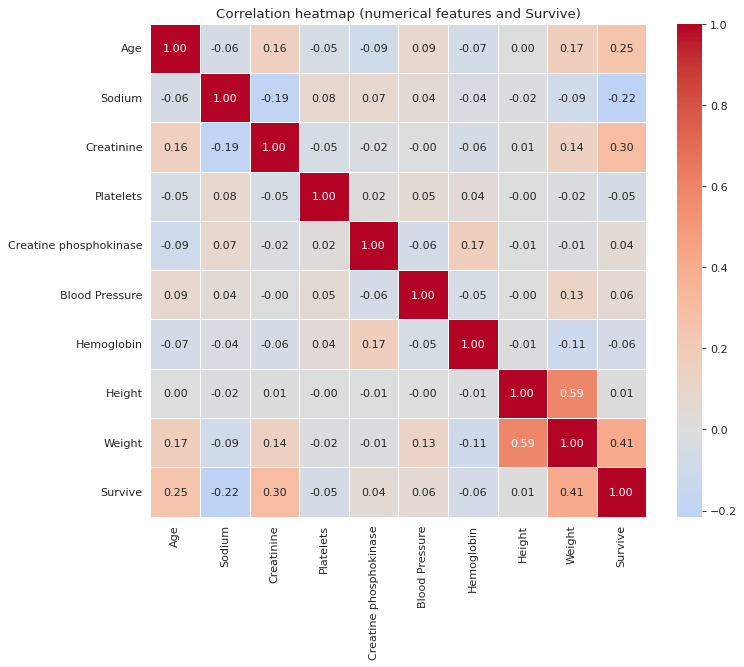

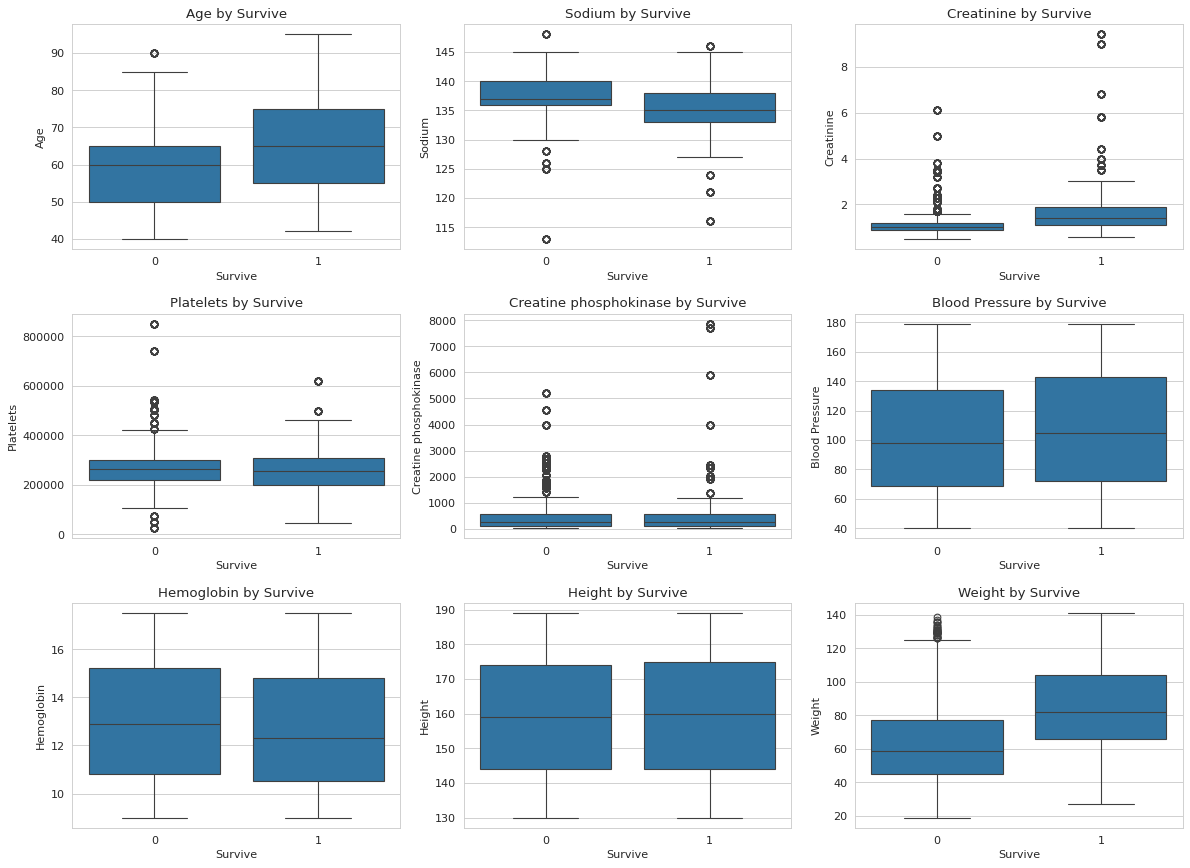

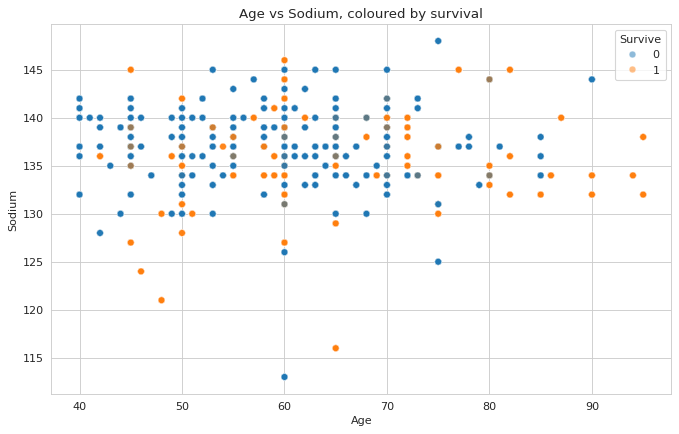

In [ ]:
numeric_cols = ['Age', 'Sodium', 'Creatinine', 'Platelets', 'Creatine phosphokinase',
                'Blood Pressure', 'Hemoglobin', 'Height', 'Weight']

# 1. Correlation heatmap across the numerical features (plus the target)
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols + ['Survive']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation heatmap (numerical features and Survive)')
plt.show()

# 2. Each numerical feature grouped by survival
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.boxplot(x='Survive', y=col, data=df, ax=ax)
    ax.set_title(f'{col} by Survive')
plt.tight_layout()
plt.show()

# 3. Scatter plot: Age vs Sodium coloured by survival (3,000-row sample to avoid overplotting)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df.sample(3000, random_state=42), x='Age', y='Sodium', hue='Survive', alpha=0.5)
plt.title('Age vs Sodium, coloured by survival')
plt.show()

# 4. Grouped summaries: survival rate by categorical feature, compared with the overall rate
baseline = df['Survive'].mean()
print(f'Overall survival rate: {baseline:.3f}\n')
for col in ['Ejection Fraction', 'Diabetes', 'Smoke', 'Gender']:
    summary = df.groupby(col)['Survive'].agg(['mean', 'count'])
    summary['diff_from_overall'] = summary['mean'] - baseline
    print(summary.sort_values('mean', ascending=False).round(3), '\n')

# 5. Two-way view: survival rate by Ejection Fraction and Diabetes
print(df.pivot_table(values='Survive', index='Ejection Fraction', columns='Diabetes', aggfunc='mean').round(3))

**What the interactions show:**

- **Correlation heatmap:** the features most correlated with survival are `Weight` (0.41), `Creatinine` (0.30), `Age` (0.25) and `Sodium` (-0.22); `Height` is essentially unrelated (0.01). `Height` and `Weight` are moderately correlated with each other (|r| = 0.59), which is expected, and every other pair is weaker (at most 0.19), so multicollinearity is not a serious concern.
- **Boxplots by outcome:** survivors have a higher median `Weight` (82 vs 59), `Creatinine` (1.4 vs 1.0) and `Age` (65 vs 60), and a lower median `Sodium` (135 vs 137). `Platelets`, `Blood Pressure`, `Hemoglobin`, `Height` and `Creatine phosphokinase` barely differ between the groups.
- **Age vs Sodium scatter:** the two are almost uncorrelated with each other (r = -0.06), so each contributes on its own, consistent with the medians above.
- **Categorical features:** survival rate falls with `Ejection Fraction` (33.9% for Low, 19.2% for Normal, 0% for High, but only 60 High patients). `Diabetes`, `Smoke` and `Gender` show no signal: their survival rates differ by at most 1.2 percentage points. The `Ejection Fraction` by `Diabetes` table shows the same ordering at every diabetes level, so there is no interaction between them.

ROC AUC as a single predictor -> BMI: 0.833 | Weight: 0.750 | Height: 0.504

          mean  count
BMI                  
<18.5    0.047   2351
18.5-25  0.197   3560
25-30    0.158   2768
30-35    0.311   3572
35+      0.893   2747


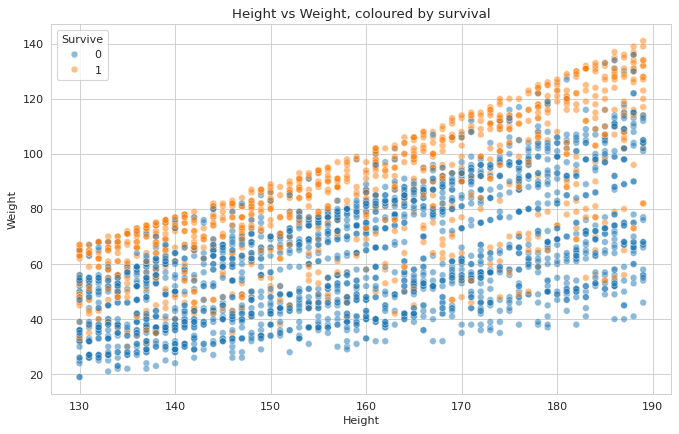

In [ ]:
# Interaction hypothesis: weight only matters relative to height, i.e. BMI (kg / m^2)
from sklearn.metrics import roc_auc_score

bmi = (df['Weight'] / (df['Height'] / 100) ** 2).rename('BMI')
print(f"ROC AUC as a single predictor -> BMI: {roc_auc_score(df['Survive'], bmi):.3f} | "
      f"Weight: {roc_auc_score(df['Survive'], df['Weight']):.3f} | Height: {roc_auc_score(df['Survive'], df['Height']):.3f}\n")

bands = pd.cut(bmi, [0, 18.5, 25, 30, 35, float('inf')], labels=['<18.5', '18.5-25', '25-30', '30-35', '35+'])
print(df.groupby(bands, observed=True)['Survive'].agg(['mean', 'count']).round(3))

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df.assign(BMI=bmi).sample(3000, random_state=42), x='Height', y='Weight', hue='Survive', alpha=0.5)
plt.title('Height vs Weight, coloured by survival')
plt.show()

**Weight relative to height (BMI) is a real interaction.** `Height` on its own is useless (single-feature ROC AUC 0.50) and `Weight` is moderate (0.75), but their combination, BMI, is a clearly stronger single predictor (0.83). Survival by BMI band is strongly non-linear: 5% below 18.5, 20% for 18.5 to 25, 16% for 25 to 30, 31% for 30 to 35 and 89% above 35. BMI is not added as a column in the pipeline because the tree-based models (random forest, gradient boosting) can already build this combination from `Weight` and `Height`, and adding it gave only a small gain for logistic regression (5-fold cross-validated ROC AUC 0.872 to 0.876). It would be the first feature to add if a simple, interpretable model is needed.

In [522]:
from sklearn.model_selection import train_test_split

# Separate the data into features and target
X = df.drop(columns='Survive')
y = df['Survive']

# Split the data into training (80%) and test-validation (20%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Split the test-validation set (20%) into validation (10%) and test (10%) sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [523]:
# Display the shapes of the splits to verify
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (11998, 13) (11998,)
Validation set shape: (1500, 13) (1500,)
Test set shape: (1500, 13) (1500,)


## Feature Scaling

In [524]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Define numerical features to be standardized
numerical_features = ['Age', 'Sodium', 'Creatinine', 'Platelets','Creatine phosphokinase','Blood Pressure','Hemoglobin','Height','Weight']

# Create a numerical transformer pipeline
numerical_transformer = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),   # impute first ...
    ('scaler', StandardScaler())                    # ... then scale
])

## Feature Encoding

In [525]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Define nominal features to be one-hot encoded
nominal_features = ['Smoke', 'Gender']

# Define ordinal features to be ordinally encoded
ordinal_features = ['Ejection Fraction', 'Diabetes']

# Define the ordinal categories (ordered from lowest to highest)
ejection_fraction_categories = ['Low', 'Normal', 'High']
diabetes_categories = ['Normal','Pre-diabetes', 'Diabetes']

# Create a nominal transformer pipeline
nominal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Create an ordinal transformer pipeline
ordinal_transformer = Pipeline(steps=[
    ('ordinal', OrdinalEncoder(
        categories=[ejection_fraction_categories, diabetes_categories],
        handle_unknown='use_encoded_value',
        unknown_value=-1))
])

In [526]:
from sklearn.compose import ColumnTransformer

# Combine transformers into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('nom', nominal_transformer, nominal_features),
        ('ord', ordinal_transformer, ordinal_features),
    ],
    n_jobs=-1
    )

## Feature importance

The earlier tables and plots are descriptive. To rank features in the context of a fitted model before the formal modelling section, I use **permutation importance** on the held-out validation set: each original column is shuffled and the drop in ROC AUC is measured. A random forest is used because it captures non-linear effects and interactions. Permutation importance is computed on the validation set (not the training set) so that it does not reward memorisation, and it is reported per original column instead of per one-hot column. The forest's own impurity-based importance is shown for comparison.

Random forest validation ROC AUC: 1.0000

                          mean     std
Creatinine              0.0418  0.0014
Weight                  0.0144  0.0010
Creatine phosphokinase  0.0045  0.0007
Sodium                  0.0029  0.0005
Age                     0.0026  0.0004
Platelets               0.0009  0.0002
Gender                  0.0001  0.0000
Hemoglobin              0.0001  0.0000
Smoke                   0.0000  0.0000
Height                  0.0000  0.0000
Blood Pressure          0.0000  0.0000
Diabetes                0.0000  0.0000
Ejection Fraction       0.0000  0.0000

                        impurity importance
Creatinine                           0.2071
Weight                               0.1431
Creatine phosphokinase               0.1362
Age                                  0.1244
Sodium                               0.1150
Platelets                            0.1099
Hemoglobin                           0.0281
Gender                               0.0276
Height         

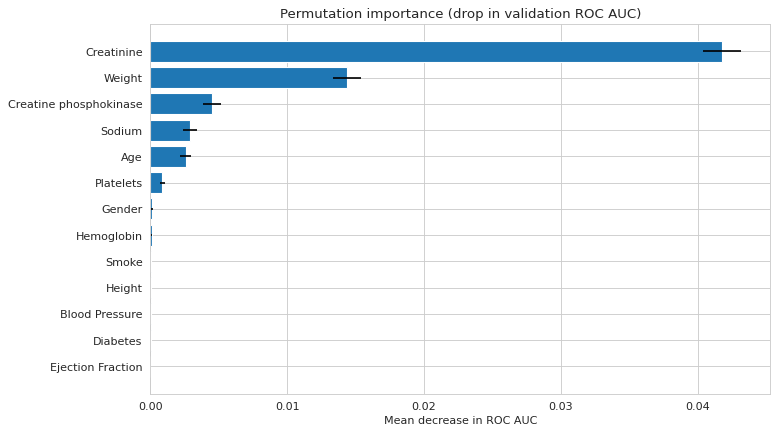

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

# Fit a random forest on the training data and measure importance on the held-out validation set
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                          class_weight='balanced', n_jobs=-1, random_state=42))
])
rf_pipeline.fit(X_train, y_train)
rf_val_auc = roc_auc_score(y_val, rf_pipeline.predict_proba(X_val)[:, 1])
print(f'Random forest validation ROC AUC: {rf_val_auc:.4f}\n')

# Permutation importance: drop in ROC AUC when one original column is shuffled
perm = permutation_importance(rf_pipeline, X_val, y_val, scoring='roc_auc',
                              n_repeats=5, random_state=42, n_jobs=1)
importance = (pd.DataFrame({'mean': perm.importances_mean, 'std': perm.importances_std},
                           index=X_val.columns)
                .sort_values('mean', ascending=False))
print(importance.round(4))

plt.figure(figsize=(10, 6))
plt.barh(importance.index[::-1], importance['mean'][::-1], xerr=importance['std'][::-1])
plt.title('Permutation importance (drop in validation ROC AUC)')
plt.xlabel('Mean decrease in ROC AUC')
plt.show()

# Compare with the model's own impurity-based importance, aggregated back to the original columns
impurity = pd.Series(rf_pipeline.named_steps['classifier'].feature_importances_,
                     index=rf_pipeline.named_steps['preprocessor'].get_feature_names_out())
original_cols = [c for c in X_val.columns]
aggregated = {c: impurity[[n for n in impurity.index if n.split('__', 1)[1].startswith(c)]].sum()
              for c in original_cols}
print()
print(pd.Series(aggregated).sort_values(ascending=False).round(4).rename('impurity importance').to_frame())

**What the importance ranking shows:**

- **Most important:** `Creatinine`, `Weight`, `Creatine phosphokinase`, `Sodium`, `Age`, `Platelets`, in that order. `Creatinine` is clearly first (a drop of 0.042 in ROC AUC), followed by `Weight` (0.014); the other four each cost under 0.005.
- **No measurable importance:** `Gender`, `Hemoglobin`, `Smoke`, `Height`, `Blood Pressure`, `Diabetes`, `Ejection Fraction`. This agrees with the interaction analysis for `Gender`, `Smoke`, `Diabetes` and `Height`, which showed no relationship with survival.
- **`Ejection Fraction` is the exception.** It looked informative in the grouped summary (0% survival for High, 19% for Normal), yet it has about zero permutation importance. The `High` group is tiny (60 patients) and its effect probably overlaps with the lab values, so the signal is weak and I would not rely on it.
- **Impurity importance** puts the same six features on top (in a slightly different order), but it also gives every other feature a small non-zero score even when there is no real signal, so the permutation ranking is the cleaner one.
- **A caution about the scores:** this random forest reaches a validation ROC AUC of 1.000 (to three decimals), which is unusually high for clinical data. The classes are almost perfectly separable by thresholds on the lab and body measurements above. I found no sign of leakage (the repeated IDs are different patients and no identifier or target-derived column is used), so this looks like a property of the dataset, but it means the model scores should not be expected to carry over to real patient data.
- **Candidates to drop** if a simpler model is wanted: `Gender`, `Hemoglobin`, `Smoke`, `Height`, `Blood Pressure`, `Diabetes`, `Ejection Fraction`.

## Logistic Regression

In [527]:
# Import the necessary library
from sklearn.linear_model import LogisticRegression

# Create the pipeline with a logistic regression model
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),  # Use the preprocessor pipeline defined earlier
    ('classifier', LogisticRegression(max_iter=1000))
])

# Fit the pipeline to the training data
logreg_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = logreg_pipeline.predict(X_val)

In [528]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate the classification metrics for Logistic Regression
logreg_val_accuracy = accuracy_score(y_val, y_val_pred)

# Display the metrics for Logistic Regression
print("Logistic Regression Metrics:")
print(f'LogReg Validation Accuracy: {logreg_val_accuracy:.5f}')

Logistic Regression Metrics:
LogReg Validation Accuracy: 0.83733


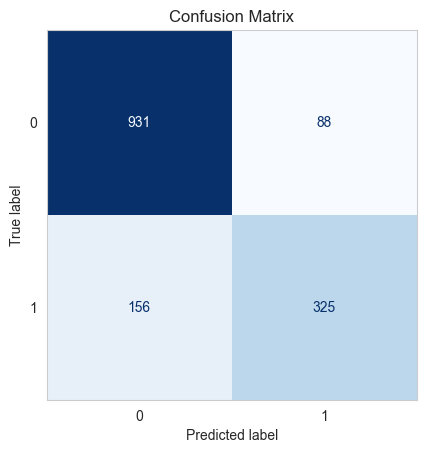

In [529]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
fig, ax = plt.subplots()
disp.plot(cmap=plt.cm.Blues, ax=ax, colorbar=False)
plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

In [530]:
# Calculate the classification metrics for Logistic Regression
logreg_val_precision = precision_score(y_val, y_val_pred)
logreg_val_recall = recall_score(y_val, y_val_pred)
logreg_val_f1 = f1_score(y_val, y_val_pred)

# Display the metrics for Logistic Regression
print("Logistic Regression Metrics:")
print(f'LogReg Validation Precision: {logreg_val_precision:.5f}')
print(f'LogReg Validation Recall: {logreg_val_recall:.5f}')
print(f'LogReg Validation F1 Score: {logreg_val_f1:.5f}')

Logistic Regression Metrics:
LogReg Validation Precision: 0.78692
LogReg Validation Recall: 0.67568
LogReg Validation F1 Score: 0.72707


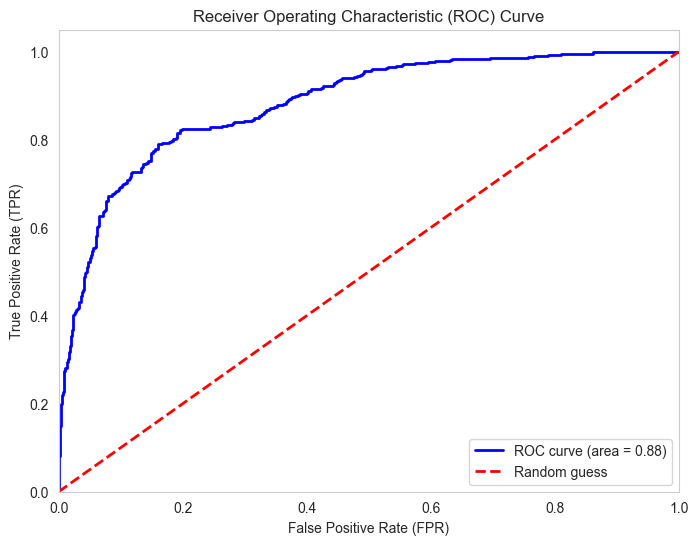

In [531]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt  

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_val, logreg_pipeline.predict_proba(X_val)[:, 1])

# Calculate the AUC
roc_auc = roc_auc_score(y_val, logreg_pipeline.predict_proba(X_val)[:, 1])

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate (FPR)')  
plt.ylabel('True Positive Rate (TPR)')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc='lower right')  
plt.grid()  
plt.show()

## KNN

In [532]:
from sklearn.neighbors import KNeighborsClassifier

# Create the pipeline with a KNN classifier
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), # Use the preprocessor pipeline defined earlier
    ('classifier', KNeighborsClassifier(n_neighbors=5)) # You can choose the number of neighbors (k) as desired
])

# Fit the pipeline to the training data
knn_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = knn_pipeline.predict(X_val)
y_val_pred_proba = knn_pipeline.predict_proba(X_val)[:, 1]

In [533]:
# Calculate and print the classification metrics for the KNN model
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred)
val_recall = recall_score(y_val, y_val_pred)
val_f1 = f1_score(y_val, y_val_pred)
val_roc_auc = roc_auc_score(y_val, y_val_pred_proba)

print("K-Nearest Neighbors (KNN) Metrics:")
print(f'Validation Accuracy: {val_accuracy:.5f}')
print(f'Validation Precision: {val_precision:.5f}')  
print(f'Validation Recall: {val_recall:.5f}')  
print(f'Validation F1 Score: {val_f1:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc:.5f}')

K-Nearest Neighbors (KNN) Metrics:
Validation Accuracy: 0.99200
Validation Precision: 0.98351
Validation Recall: 0.99168
Validation F1 Score: 0.98758
Validation ROC AUC: 0.99766


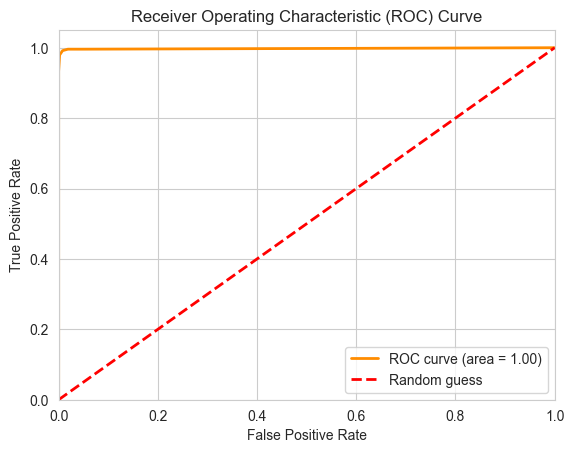

In [534]:
# Plot the ROC curve
fpr, tpr, thresholds = roc_curve(y_val, knn_pipeline.predict_proba(X_val)[:, 1])
roc_auc = roc_auc_score(y_val, knn_pipeline.predict_proba(X_val)[:, 1])

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()

## Decision tree

In [535]:
from sklearn.tree import DecisionTreeClassifier

# Create the pipeline with a Decision Tree classifier
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(criterion='gini', min_samples_split=2, max_depth=None, random_state=42))  
])

# Fit the pipeline to the training data
dt_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = dt_pipeline.predict(X_val)
y_val_pred_proba = dt_pipeline.predict_proba(X_val)[:, 1]

# Calculate metrics for the validation set
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred)  
val_recall = recall_score(y_val, y_val_pred)  
val_f1 = f1_score(y_val, y_val_pred)  
val_roc_auc = roc_auc_score(y_val, y_val_pred_proba)  

# Calculate metrics for the training set
y_train_pred = dt_pipeline.predict(X_train)  
y_train_pred_proba = dt_pipeline.predict_proba(X_train)[:, 1]  

train_accuracy = accuracy_score(y_train, y_train_pred)  
train_precision = precision_score(y_train, y_train_pred)  
train_recall = recall_score(y_train, y_train_pred)  
train_f1 = f1_score(y_train, y_train_pred)  
train_roc_auc = roc_auc_score(y_train, y_train_pred_proba)  

print("Decision Tree Classifier Validation Metrics:")
print(f'Validation Accuracy: {val_accuracy:.5f}')
print(f'Validation Precision: {val_precision:.5f}')  
print(f'Validation Recall: {val_recall:.5f}')  
print(f'Validation F1 Score: {val_f1:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc:.5f}')  

print("Training Set Metrics:")
print(f'Training Accuracy: {train_accuracy:.5f}')  
print(f'Training Precision: {train_precision:.5f}')  
print(f'Training Recall: {train_recall:.5f}')  
print(f'Training F1 Score: {train_f1:.5f}')  
print(f'Training ROC AUC: {train_roc_auc:.5f}')

Decision Tree Classifier Validation Metrics:
Validation Accuracy: 0.99200
Validation Precision: 0.99368
Validation Recall: 0.98129
Validation F1 Score: 0.98745
Validation ROC AUC: 0.98917
Training Set Metrics:
Training Accuracy: 1.00000
Training Precision: 1.00000
Training Recall: 1.00000
Training F1 Score: 1.00000
Training ROC AUC: 1.00000


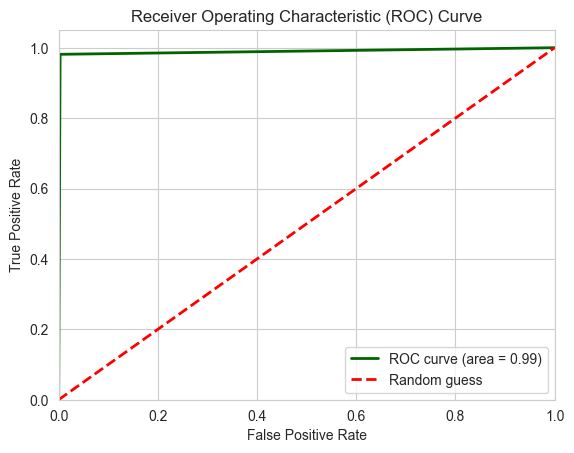

In [536]:
fpr, tpr, thresholds = roc_curve(y_val, y_val_pred_proba)
roc_auc = roc_auc_score(y_val, y_val_pred_proba)

plt.figure()  
plt.plot(fpr, tpr, color='darkgreen', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()

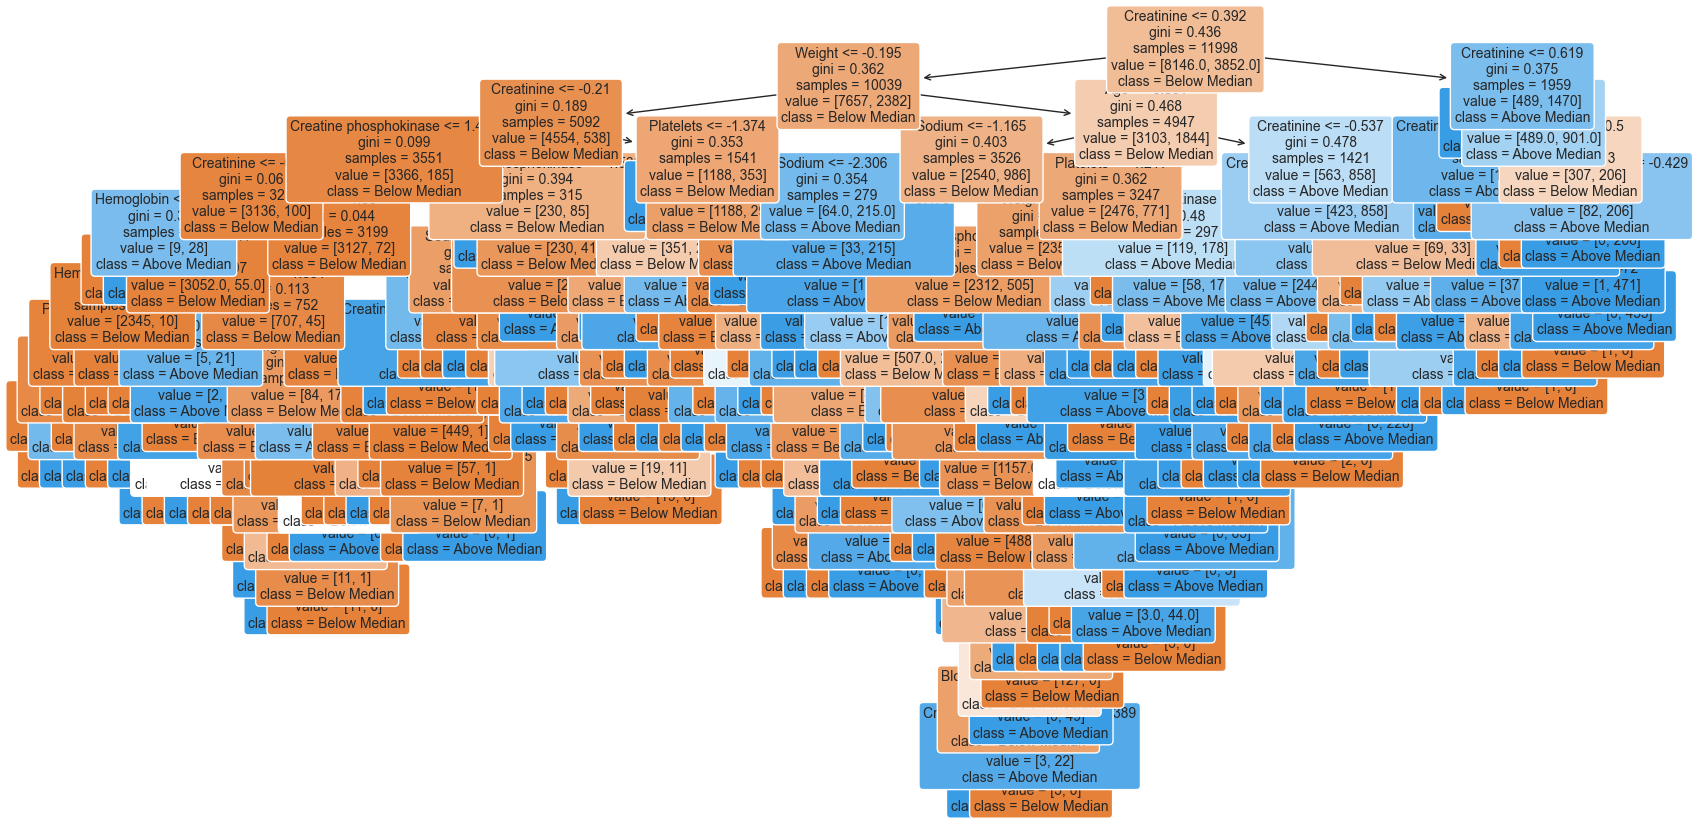

In [537]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Extract the transformed feature names
feature_names = []
for name, transformer, columns in dt_pipeline.named_steps['preprocessor'].transformers_:
    if hasattr(transformer, 'named_steps'):
        for step in transformer.named_steps.values():
            if hasattr(step, 'get_feature_names_out'):
                feature_names.extend(step.get_feature_names_out(columns))
    elif hasattr(transformer, 'get_feature_names_out'):
        feature_names.extend(transformer.get_feature_names_out(columns))
    else:
        feature_names.extend(columns)
				
# Plot the decision tree
plt.figure(figsize=(20, 10))
plot_tree(dt_pipeline.named_steps['classifier'], feature_names=feature_names, class_names=['Below Median', 'Above Median'], filled=True, rounded=True, fontsize=10)
plt.show()

### Pruning

In [538]:
# Create the new pipeline with a Decision Tree classifier with new max_depth pre-pruning parameter
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(criterion='gini', min_samples_split=2, max_depth=5, min_samples_leaf=1, random_state=42))
])  

# Fit the pipeline to the training data
dt_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = dt_pipeline.predict(X_val)
y_val_pred_proba = dt_pipeline.predict_proba(X_val)[:, 1]

# Calculate metrics for the validation set
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred)  
val_recall = recall_score(y_val, y_val_pred)  
val_f1 = f1_score(y_val, y_val_pred)  
val_roc_auc = roc_auc_score(y_val, y_val_pred_proba)  

# Calculate metrics for the training set
y_train_pred = dt_pipeline.predict(X_train)  
y_train_pred_proba = dt_pipeline.predict_proba(X_train)[:, 1]  

train_accuracy = accuracy_score(y_train, y_train_pred)  
train_precision = precision_score(y_train, y_train_pred)  
train_recall = recall_score(y_train, y_train_pred)  
train_f1 = f1_score(y_train, y_train_pred)  
train_roc_auc = roc_auc_score(y_train, y_train_pred_proba)  

print("Decision Tree Classifier Validation Metrics:")
print(f'Validation Accuracy: {val_accuracy:.5f}')
print(f'Validation Precision: {val_precision:.5f}')  
print(f'Validation Recall: {val_recall:.5f}')  
print(f'Validation F1 Score: {val_f1:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc:.5f}')  

print("Training Set Metrics:")
print(f'Training Accuracy: {train_accuracy:.5f}')  
print(f'Training Precision: {train_precision:.5f}')  
print(f'Training Recall: {train_recall:.5f}')  
print(f'Training F1 Score: {train_f1:.5f}')  
print(f'Training ROC AUC: {train_roc_auc:.5f}')

Decision Tree Classifier Validation Metrics:
Validation Accuracy: 0.85667
Validation Precision: 0.80505
Validation Recall: 0.72973
Validation F1 Score: 0.76554
Validation ROC AUC: 0.90162
Training Set Metrics:
Training Accuracy: 0.86748
Training Precision: 0.83521
Training Recall: 0.73157
Training F1 Score: 0.77996
Training ROC AUC: 0.91328


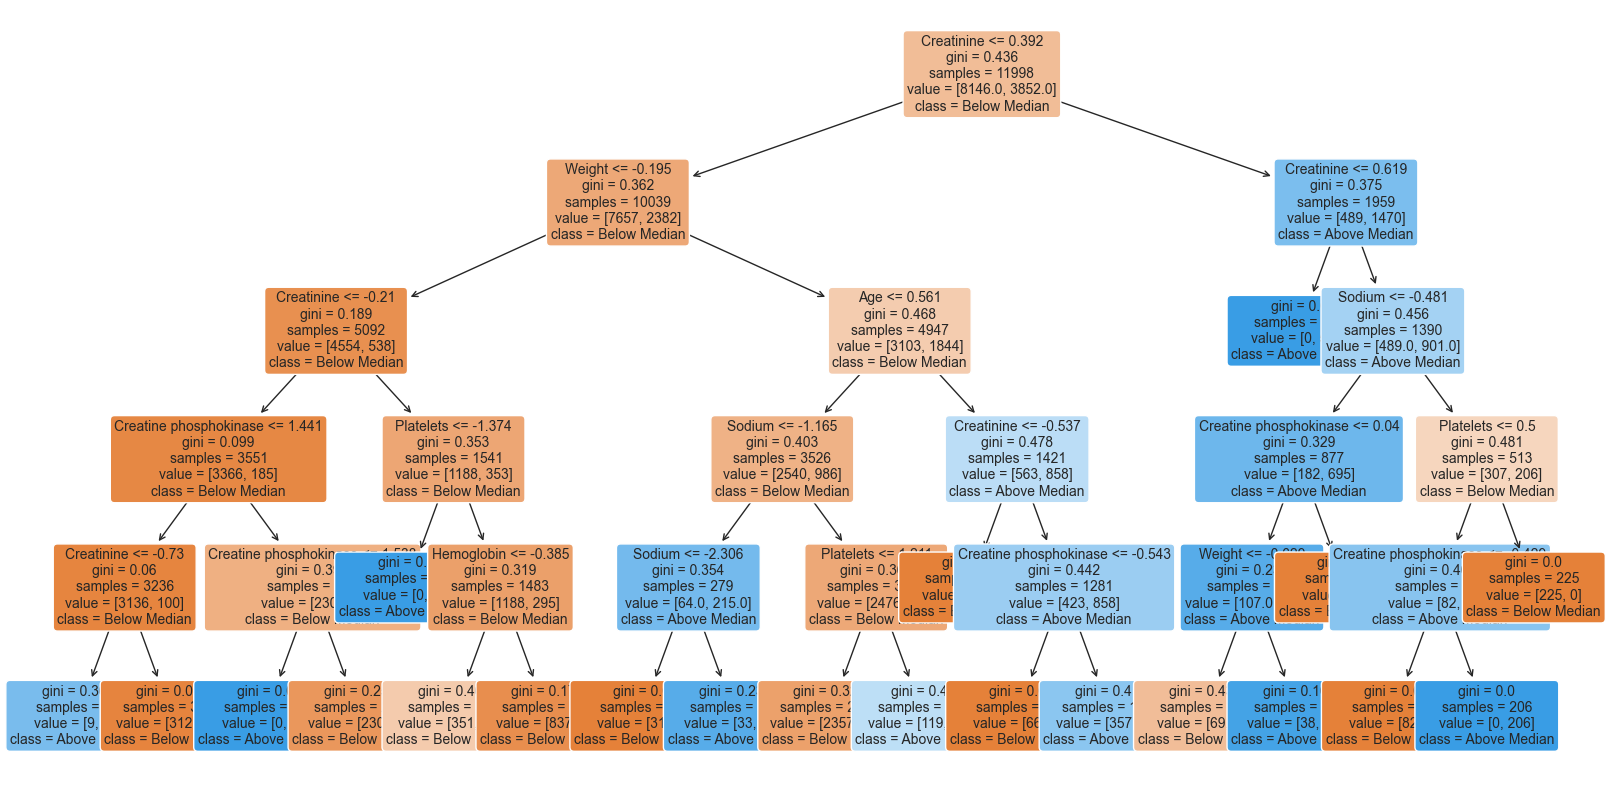

In [539]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Extract the transformed feature names
feature_names = []
for name, transformer, columns in dt_pipeline.named_steps['preprocessor'].transformers_:
    if hasattr(transformer, 'named_steps'):
        for step in transformer.named_steps.values():
            if hasattr(step, 'get_feature_names_out'):
                feature_names.extend(step.get_feature_names_out(columns))
    elif hasattr(transformer, 'get_feature_names_out'):
        feature_names.extend(transformer.get_feature_names_out(columns))
    else:
        feature_names.extend(columns)
				
# Plot the decision tree
plt.figure(figsize=(20, 10))
plot_tree(dt_pipeline.named_steps['classifier'], feature_names=feature_names, class_names=['Below Median', 'Above Median'], filled=True, rounded=True, fontsize=10)
plt.show()

In [540]:
from sklearn.model_selection import GridSearchCV

logreg_param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1.0, 10, 100, 1000],
    'classifier__penalty': ['l2', None]
}

logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),  # Use the preprocessor pipeline defined earlier
    ('classifier', LogisticRegression(max_iter=1000))
])

knn_param_grid = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11, 15],
    'classifier__weights': ['uniform', 'distance']
}

knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), # Use the preprocessor pipeline defined earlier
    ('classifier', KNeighborsClassifier()) # You can choose the number of neighbors (k) as desired
])

dt_param_grid = {
    'classifier__max_depth': [3, 5, 7, 10],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(criterion='gini', min_samples_split=2, min_samples_leaf=1, random_state=42))
])
# Perform grid search with cross-validation
logreg_grid_search = GridSearchCV(logreg_pipeline, logreg_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
logreg_grid_search.fit(X_train, y_train)

knn_grid_search = GridSearchCV(knn_pipeline, knn_param_grid, cv=5, scoring='accuracy', n_jobs=2)
knn_grid_search.fit(X_train, y_train)

dt_grid_search = GridSearchCV(dt_pipeline, dt_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
dt_grid_search.fit(X_train, y_train)

c:\Users\wongj\miniconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_logistic.py:1186: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(n_jobs=-1,
                                                          transformers=[('num',
                                                                         Pipeline(steps=[('scaler',
                                                                                          StandardScaler()),
                                                                                         ('impute',
                                                                                          SimpleImputer(strategy='median'))]),
                                                                         ['Age',
                                                                          'Sodium',
                                                                          'Creatinine',
                                                                          'Platelets',
                                                                          'Creatine '
                                                                          'phosphokinase',
                                                                          'Blood '
                                                                          'Pressure',
                                                                          'Hemoglobin',
                                                                          'Height',
                                                                          'Weight']),
                                                                        ('nom',
                                                                         Pipeline(steps=[('onehot',...
                                                                                                                      'High'],
                                                                                                                     ['Normal',
                                                                                                                      'Pre-diabetes',
                                                                                                                      'Diabetes']],
                                                                                                         handle_unknown='use_encoded_value',
                                                                                                         unknown_value=-1))]),
                                                                         ['Ejection '
                                                                          'Fraction',
                                                                          'Diabetes'])])),
                                       ('classifier',
                                        DecisionTreeClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__max_depth': [3, 5, 7, 10],
                         'classifier__min_samples_leaf': [1, 2, 4],
                         'classifier__min_samples_split': [2, 5, 10]},
             scoring='accuracy')

In [138]:
for name, gs in [('Logistic Regression', logreg_grid_search),
                 ('KNN', knn_grid_search),
                 ('Decision Tree', dt_grid_search)]:
    print(f"{name}\n  Best params: {gs.best_params_}\n  Best CV score: {gs.best_score_:.4f}\n")

Logistic Regression
  Best params: {'classifier__C': 0.001, 'classifier__penalty': None}
  Best CV score: 0.8920

KNN
  Best params: {'classifier__n_neighbors': 15, 'classifier__weights': 'distance'}
  Best CV score: 0.8801

Decision Tree
  Best params: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 10}
  Best CV score: 0.8768



K-Nearest Neighbors (KNN) Metrics:
Validation Accuracy: 0.89238
Validation Precision: 0.89010
Validation Recall: 0.89371
Validation F1 Score: 0.89190
Validation ROC AUC: 0.96232


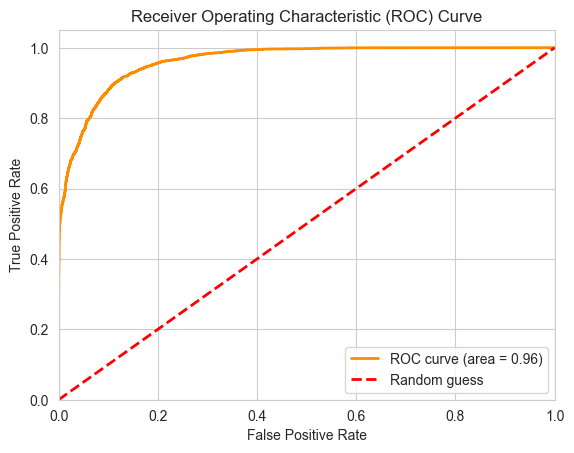

In [ ]:
# Evaluate the best Logistic Regression model on the validation set
best_logreg_model = logreg_grid_search.best_estimator_
y_val_pred_logreg = best_logreg_model.predict(X_val)
y_val_pred_proba_logreg = best_logreg_model.predict_proba(X_val)[:, 1]

val_accuracy_logreg = accuracy_score(y_val, y_val_pred_logreg)
val_precision_logreg = precision_score(y_val, y_val_pred_logreg)
val_recall_logreg = recall_score(y_val, y_val_pred_logreg)
val_f1_logreg = f1_score(y_val, y_val_pred_logreg)
val_roc_auc_logreg = roc_auc_score(y_val, y_val_pred_proba_logreg)

print("Logistics Regression (KNN) Metrics:")
print(f'Validation Accuracy: {val_accuracy_logreg:.5f}')
print(f'Validation Precision: {val_precision_logreg:.5f}')  
print(f'Validation Recall: {val_recall_logreg:.5f}')  
print(f'Validation F1 Score: {val_f1_logreg:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc_logreg:.5f}')

# Plot the ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_val_pred_proba_logreg)
roc_auc = roc_auc_score(y_val, y_val_pred_proba_logreg)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()

K-Nearest Neighbors (KNN) Metrics:
Validation Accuracy: 0.88018
Validation Precision: 0.88678
Validation Recall: 0.86988
Validation F1 Score: 0.87825
Validation ROC AUC: 0.94818


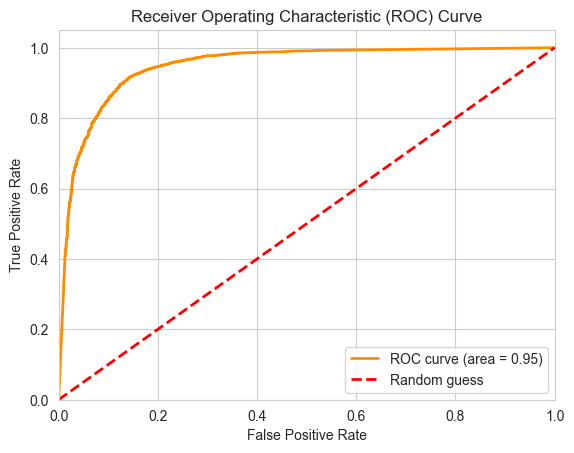

In [140]:
# Evaluate the best KNN model on the validation set
best_knn_model = knn_grid_search.best_estimator_
y_val_pred_knn = best_knn_model.predict(X_val)
y_val_pred_proba_knn = best_knn_model.predict_proba(X_val)[:, 1]

val_accuracy_knn = accuracy_score(y_val, y_val_pred_knn)
val_precision_knn = precision_score(y_val, y_val_pred_knn)
val_recall_knn = recall_score(y_val, y_val_pred_knn)
val_f1_knn = f1_score(y_val, y_val_pred_knn)
val_roc_auc_knn = roc_auc_score(y_val, y_val_pred_proba_knn)

print("K-Nearest Neighbors (KNN) Metrics:")
print(f'Validation Accuracy: {val_accuracy_knn:.5f}')
print(f'Validation Precision: {val_precision_knn:.5f}')  
print(f'Validation Recall: {val_recall_knn:.5f}')  
print(f'Validation F1 Score: {val_f1_knn:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc_knn:.5f}')

# Plot the ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_val_pred_proba_knn)
roc_auc = roc_auc_score(y_val, y_val_pred_proba_knn)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()

Decision Tree Classifier Validation Metrics:
Validation Accuracy: 0.87746
Validation Precision: 0.90999
Validation Recall: 0.83603
Validation F1 Score: 0.87144
Validation ROC AUC: 0.95044
Training Set Metrics:
Training Accuracy: 0.88384
Training Precision: 0.91851
Training Recall: 0.84077
Training F1 Score: 0.87792
Training ROC AUC: 0.95693


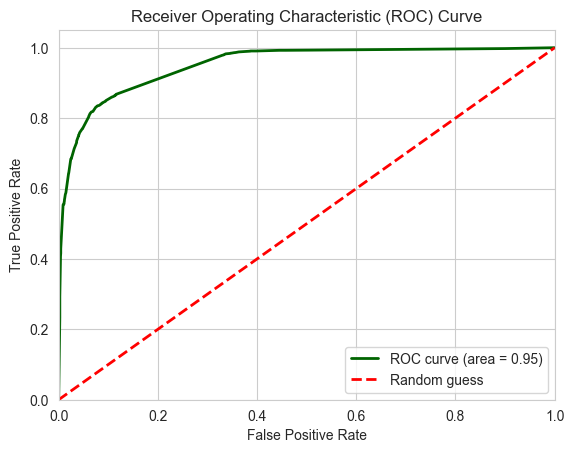

In [ ]:
# Evaluate the best Decision tree model on the validation set
# Predict on the validation set
best_dt_model = dt_grid_search.best_estimator_
y_val_pred_dt = best_dt_model.predict(X_val)
y_val_pred_proba_dt = best_dt_model.predict_proba(X_val)[:, 1]

# Calculate metrics for the validation set
val_accuracy_dt = accuracy_score(y_val, y_val_pred_dt)
val_precision_dt = precision_score(y_val, y_val_pred_dt)  
val_recall_dt = recall_score(y_val, y_val_pred_dt)  
val_f1_dt = f1_score(y_val, y_val_pred_dt)  
val_roc_auc_dt = roc_auc_score(y_val, y_val_pred_proba_dt)  

# Calculate metrics for the training set
y_train_pred_dt= best_dt_model.predict(X_train)  
y_train_pred_proba_dt = best_dt_model.predict_proba(X_train)[:, 1]  

train_accuracy_dt = accuracy_score(y_train, y_train_pred_dt)  
train_precision_dt = precision_score(y_train, y_train_pred_dt)  
train_recall_dt = recall_score(y_train, y_train_pred_dt)  
train_f1_dt = f1_score(y_train, y_train_pred_dt)  
train_roc_auc_dt = roc_auc_score(y_train, y_train_pred_proba_dt)  

print("Decision Tree Classifier Validation Metrics:")
print(f'Validation Accuracy: {val_accuracy_dt:.5f}')
print(f'Validation Precision: {val_precision_dt:.5f}')  
print(f'Validation Recall: {val_recall_dt:.5f}')  
print(f'Validation F1 Score: {val_f1_dt:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc_dt:.5f}')  

print("Training Set Metrics:")
print(f'Training Accuracy: {train_accuracy_dt:.5f}')  
print(f'Training Precision: {train_precision_dt:.5f}')  
print(f'Training Recall: {train_recall_dt:.5f}')  
print(f'Training F1 Score: {train_f1_dt:.5f}')  
print(f'Training ROC AUC: {train_roc_auc_dt:.5f}')

fpr, tpr, thresholds = roc_curve(y_val, y_val_pred_proba_dt)
roc_auc = roc_auc_score(y_val, y_val_pred_proba_dt)

plt.figure()  
plt.plot(fpr, tpr, color='darkgreen', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()